# California Housing: six clusters and supervised classification

This notebook completes the five stages of the 4Geeks K-means project. Each row represents a **1990 census block group**, not an individual house. We use only latitude, longitude and median income; housing prices are excluded. Cluster numbers are arbitrary identifiers, not rankings or verified real-world classes.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from app import (FEATURES, load_data, split_data, fit_clusters, label_data, plot_clusters,
                 fit_classifier, evaluate, save_results)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')


## 1. Load, inspect, and split

The source is the assignment-provided CSV. Check types, missing values, ranges and duplicate feature combinations. Identical feature triples remain in one split, while retaining all census-block observations. A seeded group split reserves approximately 20% for testing. Preprocessing is fitted after splitting.

In [2]:
data, audit = load_data()
display(pd.Series(audit, name='Data audit'))
display(data.head(), data.dtypes, data.describe())
train, test = split_data(data)
print(f'Training rows: {len(train):,}; test rows: {len(test):,}')
assert set(train.index).isdisjoint(test.index)
assert not set(map(tuple, train.to_numpy())).intersection(map(tuple, test.to_numpy()))

source                    https://breathecode.herokuapp.com/asset/intern...
sha256                    0e4a0bc8b337d88c95259a8ec05a58c662f26f87487f9c...
rows                                                                  20640
features                                      [Latitude, Longitude, MedInc]
missing_values                 {'Latitude': 0, 'Longitude': 0, 'MedInc': 0}
duplicate_feature_rows                                                    5
Name: Data audit, dtype: object

,Latitude,Longitude,MedInc
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462


Latitude     float64
Longitude    float64
MedInc       float64
dtype: object

,Latitude,Longitude,MedInc
count,20640.000000,20640.000000,20640.000000
mean,35.631861,-119.569704,3.870671
std,2.135952,2.003532,1.899822
min,32.540000,-124.350000,0.499900
25%,33.930000,-121.800000,2.563400
50%,34.260000,-118.490000,3.534800
75%,37.710000,-118.010000,4.743250
max,41.950000,-114.310000,15.000100


Training rows: 16,512; test rows: 4,128


## 2. Train K-means with six clusters

StandardScaler gives location and income comparable influence in Euclidean distance; otherwise their numerical units determine weighting. Both scaling and K-means are fitted on training data only. We explicitly use six clusters, seed 42, and 20 initializations. No price target is involved.

Cluster dtype: category
Cluster IDs: [0, 1, 2, 3, 4, 5]


,count,latitude_mean,longitude_mean,income_median
cluster,,,,
0,3896,38.346463,-121.892454,2.88330
1,3329,33.864665,-118.028047,5.12960
2,5333,33.817635,-117.819490,2.86500
3,2227,37.702375,-121.954809,5.21140
4,414,34.932391,-119.262923,10.27385
5,1313,36.112209,-119.714105,2.53880


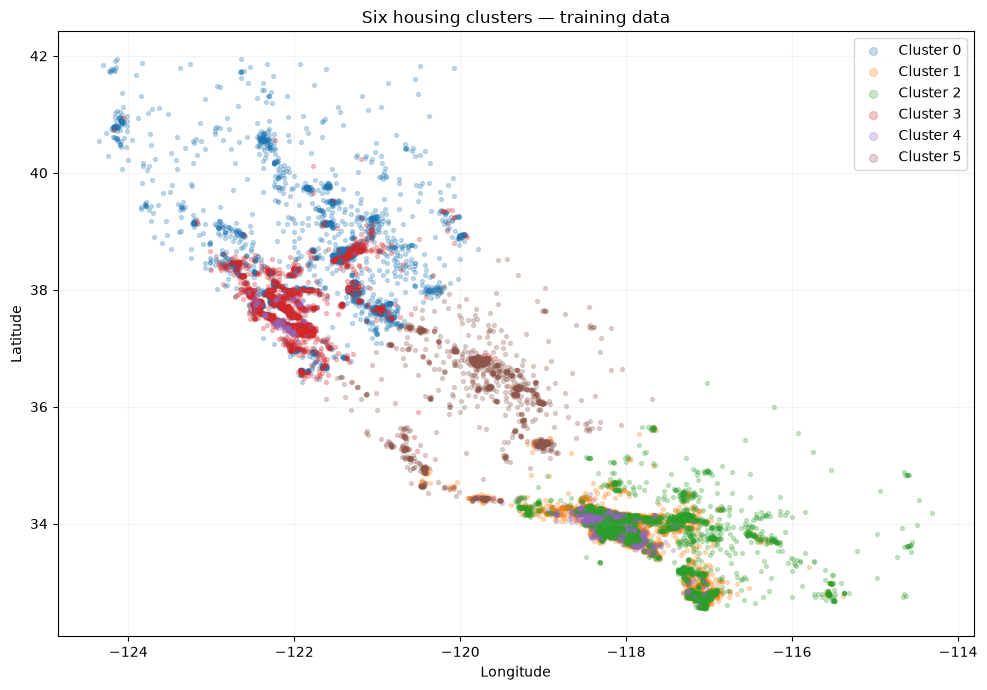

In [3]:
clustering = fit_clusters(train)
train = label_data(clustering, train)
print('Cluster dtype:', train.cluster.dtype)
print('Cluster IDs:', sorted(train.cluster.unique()))
summary = train.groupby('cluster', observed=False).agg(count=('MedInc','size'), latitude_mean=('Latitude','mean'), longitude_mean=('Longitude','mean'), income_median=('MedInc','median'))
display(summary)
fig = plot_clusters(train); display(fig); plt.close(fig)

The map is a two-dimensional projection of a three-feature clustering: groups may overlap geographically because income also affects membership. The summary table distinguishes groups by average location and median income. Cluster 0 is not inherently better or worse than cluster 5.

## 3. Predict unseen points

Use the already fitted model to assign test clusters. Test points appear as crosses over the training points, using the same cluster colors. This checks whether new observations follow the learned partitions; visual consistency is not proof of objectively correct housing categories.

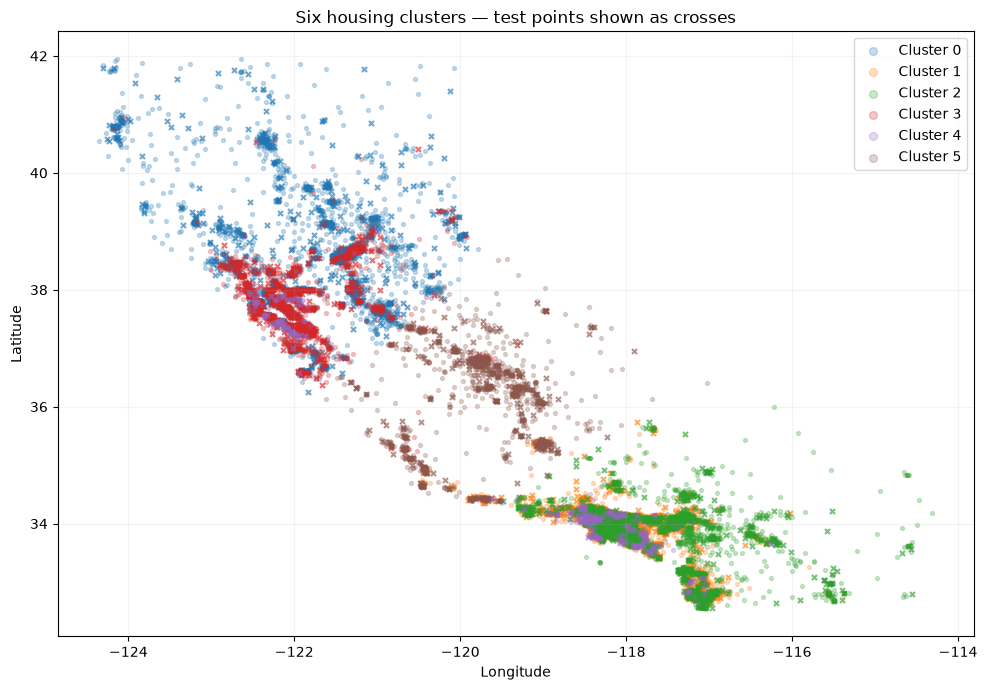

cluster
0     991
1     823
2    1329
3     532
4     109
5     344
Name: test_count, dtype: int64

In [4]:
test = label_data(clustering, test)
fig = plot_clusters(train, test); display(fig); plt.close(fig)
display(test.cluster.value_counts(sort=False).rename('test_count'))

## 4. Train and evaluate a supervised classifier

K-means provides the labels for both splits. Compare a decision tree (interpretable nonlinear boundaries) and logistic regression (linear boundaries, suited to nearest-centroid partitions). Select hyperparameters and model using five-fold stratified group cross-validation **only on training rows**, then evaluate on the untouched test rows. The cluster column is the target and is never an input. CV estimates agreement with a fixed training-only K-means teacher, not independent clustering ground truth.

In [5]:
classifier, comparison, winner = fit_classifier(train)
display(pd.DataFrame(comparison))
print('Selected classifier:', winner)
metrics, predicted = evaluate(classifier, test)
print(f"Test agreement: {metrics['accuracy']:.2%}")
display(pd.DataFrame(metrics['classification_report']).T)
display(pd.DataFrame(metrics['confusion_matrix'], index=[f'K-means {i}' for i in range(6)], columns=[f'Classifier {i}' for i in range(6)]))

,model,cv_accuracy,best_params
0,decision_tree,0.992854,"{'classifier__max_depth': 15, 'classifier__min..."
1,logistic_regression,0.995216,{'classifier__C': 10}


Selected classifier: logistic_regression
Test agreement: 99.54%


,precision,recall,f1-score,support
0,0.997982,0.997982,0.997982,991.000000
1,0.996350,0.995140,0.995745,823.000000
2,0.998492,0.996238,0.997363,1329.000000
3,0.996234,0.994361,0.995296,532.000000
4,0.972973,0.990826,0.981818,109.000000
5,0.979827,0.988372,0.984081,344.000000
accuracy,0.995397,0.995397,0.995397,0.995397
macro avg,0.990310,0.993820,0.992048,4128.000000
weighted avg,0.995422,0.995397,0.995405,4128.000000


,Classifier 0,Classifier 1,Classifier 2,Classifier 3,Classifier 4,Classifier 5
K-means 0,989,0,0,0,0,2
K-means 1,0,819,1,0,2,1
K-means 2,0,1,1324,0,0,4
K-means 3,1,1,0,529,1,0
K-means 4,0,1,0,0,108,0
K-means 5,1,0,1,2,0,340


## 5. Save, reload, and verify both models

The K-means pipeline contains its fitted scaler. The classifier pipeline contains any preprocessing it needs. Saving complete pipelines preserves feature handling for future predictions. Repeated predictions after reloading must match exactly. Outputs include cluster summaries, centroids, split data, plots and a machine-readable evaluation.

{'disjoint_rows': True,
 'disjoint_feature_triples': True,
 'preprocessing_fit_on_training_only': True,
 'six_training_clusters': True,
 'saved_models_reload_identically': True}

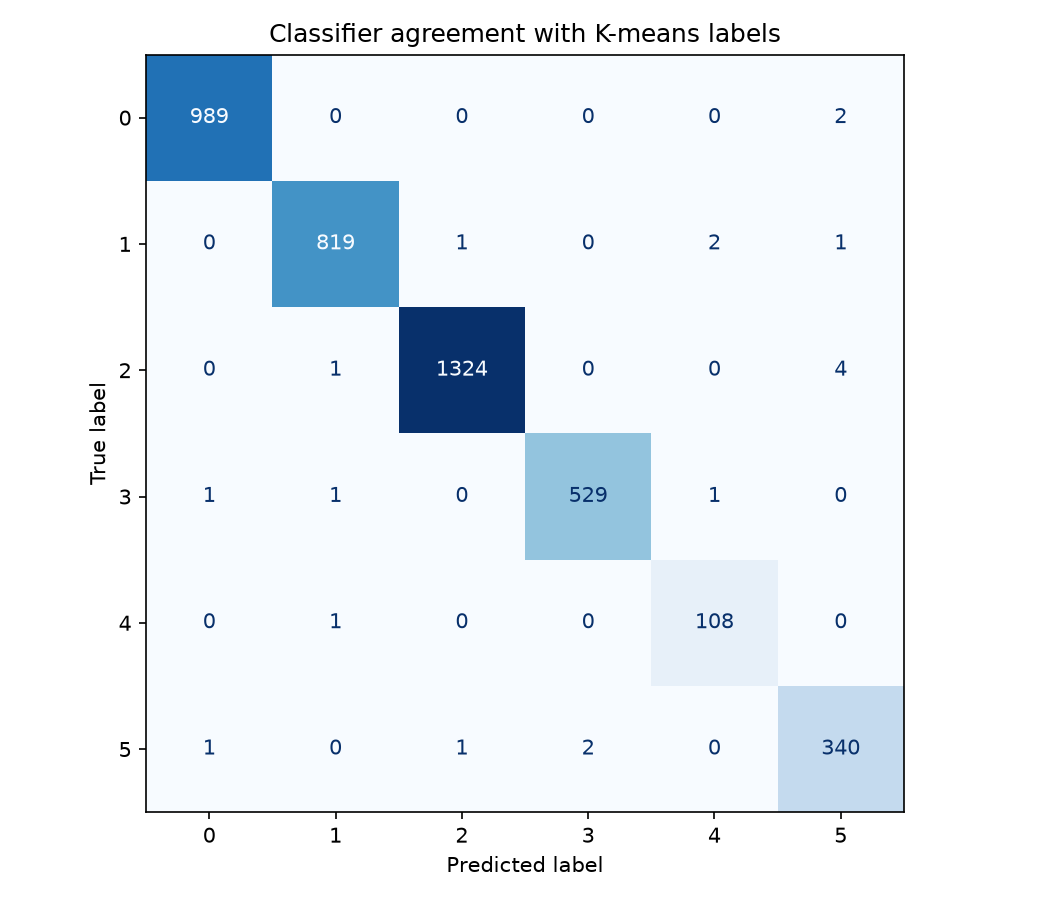

Training silhouette (seeded sample): 0.411
Saved: ['kmeans_pipeline.joblib', 'classifier_pipeline.joblib']


In [6]:
results = save_results(clustering, classifier, train, test, audit, comparison, winner, metrics, predicted)
display(results['verification'])
display(Image(filename=str(ROOT / 'reports/figures/confusion_matrix.png')))
print('Training silhouette (seeded sample):', round(results['train_silhouette_sample'], 3))
print('Saved:', [p.name for p in (ROOT / 'models').glob('*.joblib')])

## Findings and limitations

The six groups summarize geographic and income similarity. Read the displayed cluster table for the location and income characteristics of each group. The test overlay shows how held-out blocks are assigned to the same learned partitions. Classifier mistakes are disagreements near learned boundaries, not errors against human-verified classes. A high agreement score therefore does not establish socioeconomic validity.

Six clusters are prescribed by the exercise, not established as optimal. Standardized latitude/longitude distance is a simplification of geography; no geographic holdout is used. Median income is a census-block aggregate, and 1990 data does not describe today’s housing market. Predictions are educational cluster assignments, not housing valuations or eligibility decisions.

Observed cluster patterns: clusters 0 and 3 concentrate farther north, with cluster 3 having higher median income (5.21 versus 2.88 in the dataset units). Clusters 1 and 2 concentrate farther south, with median incomes 5.13 and 2.87. Cluster 4 is the smallest group (414 training blocks) and has the highest median income (10.27). Cluster 5 sits between the northern and southern concentrations and has the lowest median income (2.54). These are aggregate descriptions, not neighborhood boundaries. The classifier comparison and held-out statistics above quantify reproduction of these fixed groups.